<a href="https://colab.research.google.com/github/PanconquesoHH/Laboratorios-ia/blob/main/Aprendizaje_por_refuerzo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Este cuadernillo presenta una simulación del juego de las **Cajas del Tesoro**, donde un agente debe descubrir la opción más generosa entre 5 cajas cerradas con recompensas aleatorias. Se evalúan tres estrategias de aprendizaje por refuerzo: *Greedy* ($\epsilon=0.0$), $\epsilon$-*Greedy* ($\epsilon=0.1$) y *Upper Confidence Bound* (UCB, $c=1.0$) a lo largo de 1000 jugadas. El objetivo es comparar cómo cada algoritmo equilibra la exploración y la explotación para maximizar las monedas de oro obtenidas. Finalmente, se incluye un análisis gráfico que demuestra la alta eficiencia del algoritmo UCB y la precisión de sus estimaciones finales $Q(a)$ frente a los valores reales ocultos.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math


MEDIAS_CAJAS = [1.5, 3.0, 0.5, 5.0, 2.0]
K_CAJAS = len(MEDIAS_CAJAS)

def abrir_caja(accion):
    """
    Retorna la recompensa de monedas al abrir la caja elegida.
    Agrega un ruido Gaussiano (sigma=1.0) idéntico al cuadernillo de clase.
    """
    media_real = MEDIAS_CAJAS[accion]
    monedas = np.random.normal(loc=media_real, scale=1.0)
    return monedas


print("Prueba de apertura de la Caja 3 (Caja óptima):", abrir_caja(3))

Prueba de apertura de la Caja 3 (Caja óptima): 4.530774198331045


In [ ]:
def simular_epsilon_greedy(episodios=1000, epsilon=0.1, alpha=None):

    Q = np.zeros(K_CAJAS)
    N = np.zeros(K_CAJAS)
    historial_recompensas = []

    for t in range(1, episodios + 1):

        if np.random.rand() < epsilon:
            accion = np.random.choice(K_CAJAS)

            max_q = np.max(Q)
            mejores = [a for a in range(K_CAJAS) if Q[a] == max_q]
            accion = np.random.choice(mejores)


        recompensa = abrir_caja(accion)
        N[accion] += 1


        tasa_aprendizaje = alpha if alpha is not None else (1.0 / N[accion])
        Q[accion] += tasa_aprendizaje * (recompensa - Q[accion])

        historial_recompensas.append(recompensa)

    return Q, N, historial_recompensas

In [ ]:
def simular_ucb(episodios=1000, c=1.0):
    Q = np.zeros(K_CAJAS)
    N = np.zeros(K_CAJAS)
    historial_recompensas = []

    for t in range(1, episodios + 1):
        valores_ucb = []
        for a in range(K_CAJAS):
            if N[a] == 0:
                valores_ucb.append(float('inf'))
            else:
                incertidumbre = c * math.sqrt(math.log(t) / N[a])
                valores_ucb.append(Q[a] + incertidumbre)

        max_val = max(valores_ucb)
        mejores = [a for a in range(K_CAJAS) if valores_ucb[a] == max_val]
        accion = np.random.choice(mejores)

        recompensa = abrir_caja(accion)
        N[accion] += 1
        Q[accion] += (1.0 / N[accion]) * (recompensa - Q[accion])

        historial_recompensas.append(recompensa)

    return Q, N, historial_recompensas

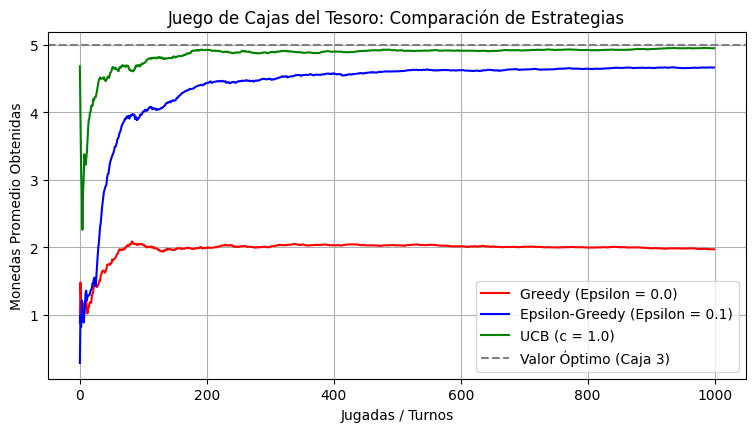

Estimación final de la Tabla Q con UCB: [ 1.97  3.03 -0.13  4.97  1.56]


In [ ]:
EPISODIOS = 1000


Q_greedy, _, r_greedy = simular_epsilon_greedy(EPISODIOS, epsilon=0.0)
Q_eps, _, r_eps = simular_epsilon_greedy(EPISODIOS, epsilon=0.1)
Q_ucb, N_ucb, r_ucb = simular_ucb(EPISODIOS, c=1.0)


prom_greedy = np.cumsum(r_greedy) / (np.arange(EPISODIOS) + 1)
prom_eps = np.cumsum(r_eps) / (np.arange(EPISODIOS) + 1)
prom_ucb = np.cumsum(r_ucb) / (np.arange(EPISODIOS) + 1)


plt.figure(figsize=(9, 4.5))
plt.plot(prom_greedy, label="Greedy (Epsilon = 0.0)", color="red")
plt.plot(prom_eps, label="Epsilon-Greedy (Epsilon = 0.1)", color="blue")
plt.plot(prom_ucb, label="UCB (c = 1.0)", color="green")
plt.axhline(y=5.0, color="gray", linestyle="--", label="Valor Óptimo (Caja 3)")

plt.title("Juego de Cajas del Tesoro: Comparación de Estrategias")
plt.xlabel("Jugadas / Turnos")
plt.ylabel("Monedas Promedio Obtenidas")
plt.grid(True)
plt.legend()
plt.show()
print("Estimación final de la Tabla Q con UCB:", np.round(Q_ucb, 2))

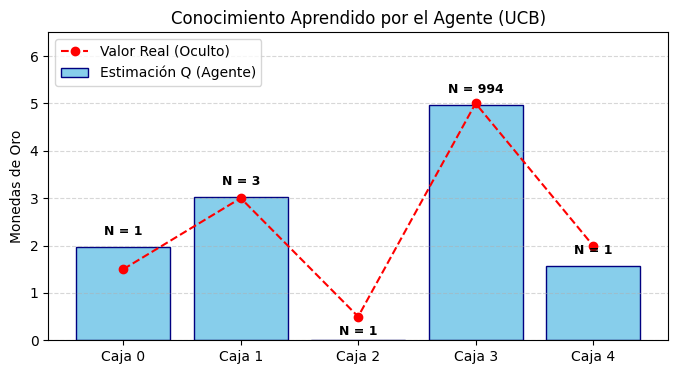

In [ ]:
import matplotlib.pyplot as plt

cajas = [f"Caja {i}" for i in range(K_CAJAS)]

plt.figure(figsize=(8, 4))


barras = plt.bar(cajas, Q_ucb, color='skyblue', edgecolor='navy', label="Estimación Q (Agente)")


plt.plot(cajas, MEDIAS_CAJAS, 'ro--', label="Valor Real (Oculto)")


for i in range(K_CAJAS):
    plt.text(i, Q_ucb[i] + 0.25, f"N = {int(N_ucb[i])}", ha='center', fontsize=9, weight='bold')

plt.ylabel("Monedas de Oro")
plt.title("Conocimiento Aprendido por el Agente (UCB)")
plt.ylim(0, 6.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.show()